# 07 – Radius counts for POI and intersections

**Problem in 06:** `poi_count` and `str_intersections` are counted only inside each 100 m cell. Most cells have 0 or 1, so a cell
can flip between clusters just because an intersection lies 5 m on the other side of the cell border. On the map this shows as "salt and pepper" in residential areas.

**Idea:** describe the **neighbourhood** instead of the cell: how many POI and intersections are within **300 m** (about a 4-minute walk).
Then cluster again with exactly the same pipeline as 06 and compare.

- **Input:** `cells.gpkg`, `ind_*.csv`, `clusters_baseline.csv` (from 06)
- **Output:** `data/processed/ind_radius.csv`, `data/processed/clusters_radius.csv`

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.ndimage import convolve
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

SEED = 0
K_RANGE = range(4, 13)
K = 6                      # same k as the baseline, so the two are directly comparable
RADIUS = 300               # m
CELL = 100                 # m
WATER_THRESHOLD = 0.5
DORM_CELL = "SIHM100_4603_1014"
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

## 2. Load

In [2]:
cells = gpd.read_file(PROCESSED / "cells.gpkg", layer="cells")
data = cells.set_index("cell_id").drop(columns="geometry")
for name in ["buildings", "land_cover", "poi", "streets"]:
    data = data.join(pd.read_csv(PROCESSED / f"ind_{name}.csv", index_col="cell_id"))
baseline = pd.read_csv(PROCESSED / "clusters_baseline.csv", index_col="cell_id")

## 3. Count within 300 m
We put the grid into a 2D array (one array cell = one grid cell) and use a **disc-shaped window**: all cells whose centre is at most 300 m from the centre cell (29 cells).
For each cell we add up the counts in the window and divide by the number of grid cells in the window, which gives **count per hectare in the neighbourhood**.

Dividing by the cells present (not always 29) matters at the MOL border: half of the disc is outside the grid there, and without this the border cells would look emptier than they are.

In [3]:
col_idx = ((data["E"] - data["E"].min()) // CELL).astype(int).values
row_idx = ((data["N"] - data["N"].min()) // CELL).astype(int).values
shape = (row_idx.max() + 1, col_idx.max() + 1)

r = RADIUS // CELL
dy, dx = np.mgrid[-r:r + 1, -r:r + 1]
disc = ((dx ** 2 + dy ** 2) * CELL ** 2 <= RADIUS ** 2).astype(float)
print(f"Window: {int(disc.sum())} cells")
print(disc.astype(int))

present = np.zeros(shape)
present[row_idx, col_idx] = 1
n_in_window = convolve(present, disc, mode="constant")

def radius_density(values):
    grid = np.zeros(shape)
    grid[row_idx, col_idx] = values
    with np.errstate(invalid="ignore"):   # 0/0 outside MOL, where there are no cells anyway
        return (convolve(grid, disc, mode="constant") / n_in_window)[row_idx, col_idx]

radius = pd.DataFrame({
    "poi_r300": radius_density(data["poi_count"].values),
    "str_intersections_r300": radius_density(data["str_intersections"].values),
}, index=data.index)

# Check: the radius versions add up to the same totals (each POI is counted once per window it falls in)
print(f"Cells with any POI:  in cell {(data['poi_count'] > 0).sum():,}  |  within 300 m {(radius['poi_r300'] > 0).sum():,}")
print(f"Cells with any intersection:  in cell {(data['str_intersections'] > 0).sum():,}  |  within 300 m "
      f"{(radius['str_intersections_r300'] > 0).sum():,}")
radius.describe().round(3).T

Window: 29 cells
[[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]
Cells with any POI:  in cell 1,523  |  within 300 m 9,352
Cells with any intersection:  in cell 2,921  |  within 300 m 14,924


,count,mean,std,min,25%,50%,75%,max
poi_r300,27505.0,0.115,0.441,0.0,0.0,0.000,0.040,10.138
str_intersections_r300,27505.0,0.168,0.279,0.0,0.0,0.034,0.238,2.828


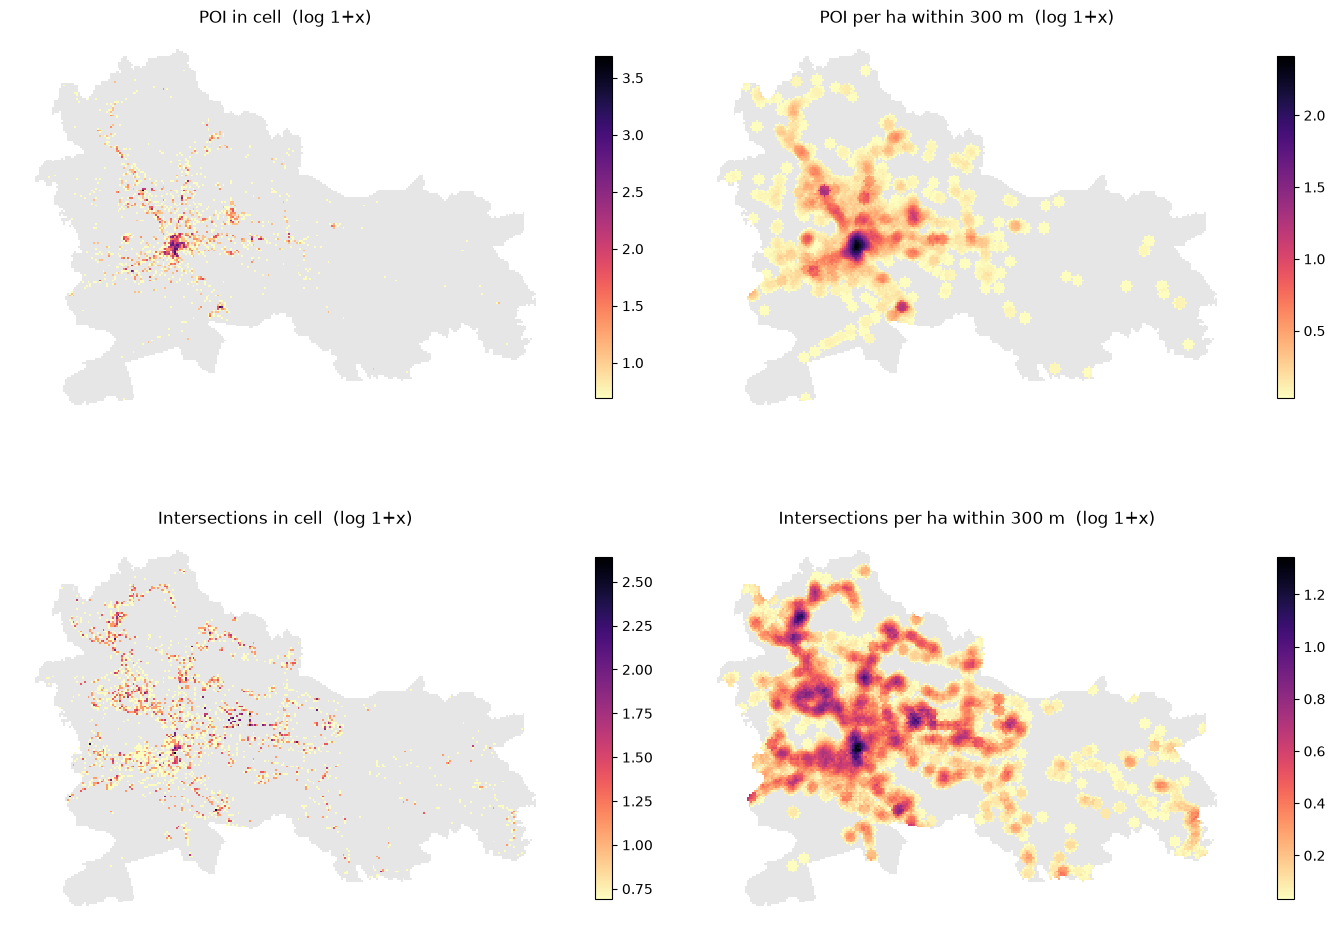

In [4]:
gdf = cells[["cell_id", "geometry"]].merge(data[["poi_count", "str_intersections"]].join(radius).reset_index(), on="cell_id")
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, col, title in [
    (axes[0, 0], "poi_count", "POI in cell"), (axes[0, 1], "poi_r300", "POI per ha within 300 m"),
    (axes[1, 0], "str_intersections", "Intersections in cell"),
    (axes[1, 1], "str_intersections_r300", "Intersections per ha within 300 m"),
]:
    gdf.plot(ax=ax, color="#e6e6e6", linewidth=0)
    sub = gdf[gdf[col] > 0]
    sub.plot(ax=ax, column=np.log1p(sub[col]), cmap="magma_r", linewidth=0, legend=True, legend_kwds={"shrink": 0.6})
    ax.set_title(f"{title}  (log 1+x)")
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(FIGURES / "07_radius_counts.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Cluster again
Exactly the same pipeline as 06 (same cells, dorm cap, log, z-score, k-means), only the two count indicators are replaced by their radius versions.

In [5]:
FEATURES = ["pop", "imp_share", "bld_height", "can_cover", "poi_r300", "str_intersections_r300"]
LOG_FEATURES = ["pop", "poi_r300", "str_intersections_r300"]

use = data["bld_in_data"] & ~(data["ndvi_neg_share"] > WATER_THRESHOLD)
X = data.loc[use].join(radius)[FEATURES].copy()
assert X.index.equals(baseline.index), "same cells as the baseline"
X.loc[DORM_CELL, "pop"] = X["pop"].drop(DORM_CELL).max()
X[LOG_FEATURES] = np.log1p(X[LOG_FEATURES])
Z = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=FEATURES)

rows, labels = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    labels[k] = km.labels_
    runs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(Z) for s in range(10)]
    aris = [adjusted_rand_score(runs[i], runs[j]) for i in range(10) for j in range(i + 1, 10)]
    rows.append({
        "k": k,
        "silhouette": silhouette_score(Z, km.labels_, sample_size=10_000, random_state=SEED),
        "davies_bouldin": davies_bouldin_score(Z, km.labels_),
        "seed_ari_mean": np.mean(aris),
        "seed_ari_min": np.min(aris),
        "smallest_cluster": np.bincount(km.labels_).min(),
    })
scores = pd.DataFrame(rows).set_index("k")
scores.round(3)

,silhouette,davies_bouldin,seed_ari_mean,seed_ari_min,smallest_cluster
k,,,,,
4,0.415,1.072,0.888,0.448,1030
5,0.434,1.071,0.997,0.993,755
6,0.420,1.071,0.862,0.752,458
7,0.396,1.183,0.788,0.589,361
8,0.399,1.186,0.862,0.650,257
9,0.403,1.150,0.881,0.655,153
10,0.403,1.137,0.847,0.686,147
11,0.399,1.211,0.805,0.669,147
12,0.363,1.158,0.800,0.652,147


## 5. Compare with the baseline
**Neighbour agreement** measures speckle: for every cell, the share of its 8 neighbours (that are clustered) that have the same cluster.
1 = every cell sits in a block of its own cluster; low values = salt and pepper. Then we average over all cells.

**ARI between baseline and radius version:** how similar the two clusterings are (1 = identical).

In [6]:
def neighbour_agreement(lab):
    grid = np.full(shape, -1)
    rr, cc = row_idx[data.index.get_indexer(lab.index)], col_idx[data.index.get_indexer(lab.index)]
    grid[rr, cc] = lab.values
    same = np.zeros(len(lab))
    total = np.zeros(len(lab))
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == dj == 0:
                continue
            ni, nj = rr + di, cc + dj
            ok = (ni >= 0) & (ni < shape[0]) & (nj >= 0) & (nj < shape[1])
            neigh = np.full(len(lab), -1)
            neigh[ok] = grid[ni[ok], nj[ok]]
            valid = neigh >= 0
            same += valid & (neigh == lab.values)
            total += valid
    return np.mean(same[total > 0] / total[total > 0])

lab_base = baseline["cluster"]
lab_rad = pd.Series(labels[K], index=Z.index)
compare = pd.DataFrame({
    "baseline (in-cell counts)": [neighbour_agreement(lab_base), np.nan],
    "radius 300 m": [neighbour_agreement(lab_rad), adjusted_rand_score(lab_base, lab_rad)],
}, index=["neighbour agreement", "ARI vs baseline"]).round(3)
compare

,baseline (in-cell counts),radius 300 m
neighbour agreement,0.632,0.714
ARI vs baseline,NaN,0.807


## 6. Profile
Same heatmap as in 06. Clusters are ordered by mean imperviousness.

**Cross-table:** where do the baseline clusters end up? Rows = baseline clusters, columns = new clusters, values = share of the row.

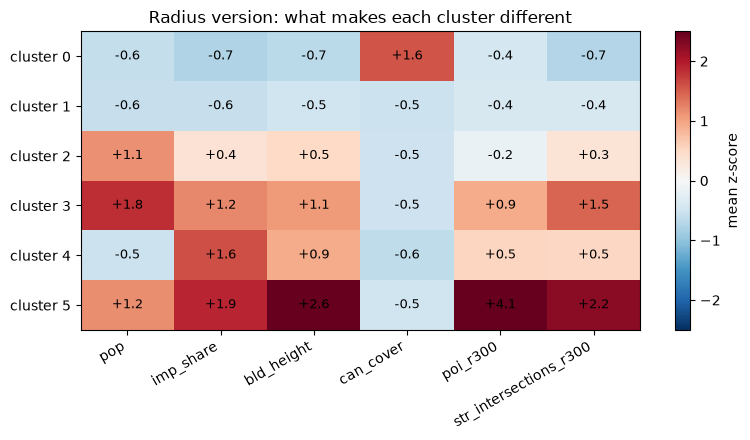

radius,0,1,2,3,4,5
baseline,,,,,,
0,0.99,0.01,0.00,0.00,0.00,0.00
1,0.01,0.94,0.03,0.00,0.02,0.00
2,0.00,0.00,0.62,0.36,0.00,0.02
3,0.00,0.05,0.35,0.47,0.09,0.04
4,0.00,0.05,0.01,0.01,0.88,0.05
5,0.01,0.01,0.04,0.35,0.20,0.40


In [7]:
order = Z.groupby(lab_rad)["imp_share"].mean().sort_values().index
lab_rad = lab_rad.map({old: new for new, old in enumerate(order)}).rename("cluster")

zmean = Z.groupby(lab_rad).mean()
fig, ax = plt.subplots(figsize=(8, 0.5 * K + 1.5))
im = ax.imshow(zmean, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=30, ha="right")
ax.set_yticks(range(K), [f"cluster {c}" for c in zmean.index])
for i in range(K):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{zmean.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="mean z-score")
ax.set_title("Radius version: what makes each cluster different")
plt.tight_layout()
fig.savefig(FIGURES / "07_profile_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

pd.crosstab(lab_base.rename("baseline"), lab_rad.rename("radius"), normalize="index").round(2)

In [8]:
prof = data.loc[Z.index].join(radius).assign(cluster=lab_rad)
g = prof.groupby("cluster")
profile = pd.DataFrame({"cells": g.size(), "residents": g["pop"].sum().astype(int)})
for col in FEATURES:
    profile[f"{col} (median)"] = g[col].median()
profile["children_0_14 %"] = 100 * g["pop_0_14"].sum() / g["pop"].sum()
profile["seniors_65+ %"] = 100 * g["pop_65plus"].sum() / g["pop"].sum()
profile["residential_share (median)"] = g["bld_residential_share"].median()
profile.round(2).T

cluster,0,1,2,3,4,5
cells,4185.000000,5952.00,2287.00,1957.000000,1512.000000,458.00
residents,360.000000,575.00,63535.00,182283.000000,483.000000,43724.00
pop (median),0.000000,0.00,20.00,65.000000,0.000000,42.00
imp_share (median),0.000000,0.00,0.31,0.560000,0.700000,0.79
bld_height (median),0.000000,0.00,7.57,9.460000,9.450000,18.67
can_cover (median),0.940000,0.06,0.07,0.090000,0.040000,0.09
poi_r300 (median),0.000000,0.00,0.07,0.410000,0.240000,1.76
str_intersections_r300 (median),0.000000,0.07,0.31,0.690000,0.380000,0.97
children_0_14 %,17.219999,11.83,14.53,13.600000,10.970000,13.02
seniors_65+ %,18.330000,29.57,19.84,20.280001,24.639999,22.23


## 7. Maps side by side

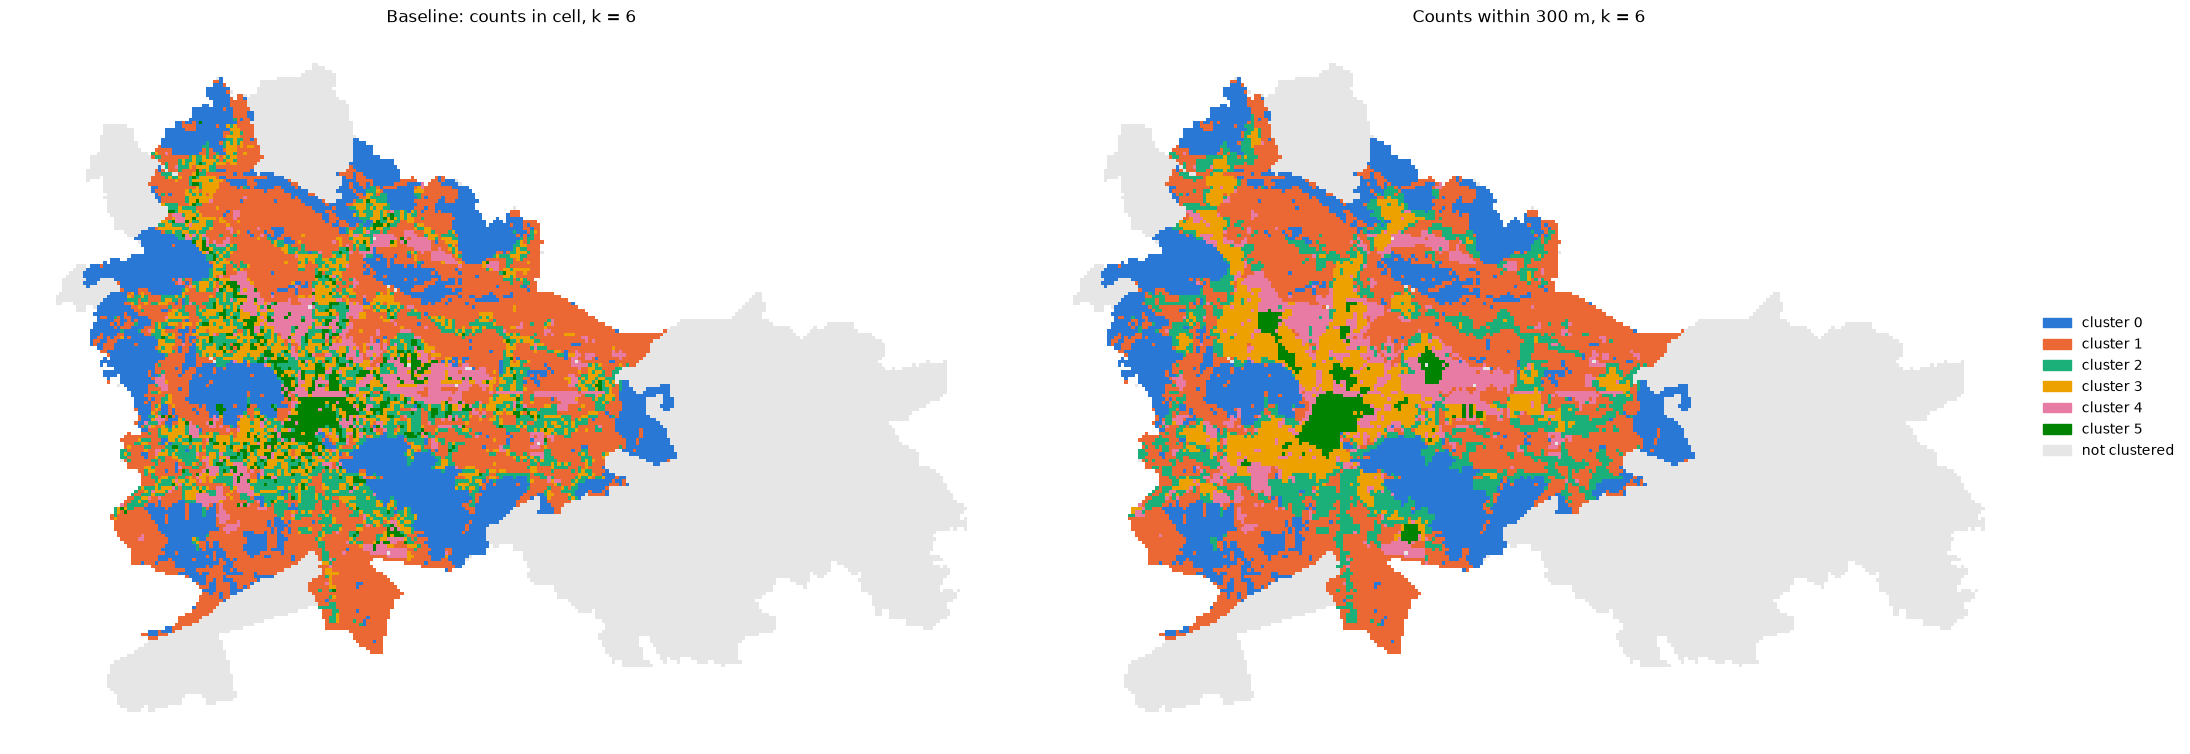

In [9]:
cmap = ListedColormap(CLUSTER_COLORS[:K])
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, lab, title in [(axes[0], lab_base, "Baseline: counts in cell"), (axes[1], lab_rad, f"Counts within {RADIUS} m")]:
    g_ = cells[["cell_id", "geometry"]].merge(lab.rename("cluster").reset_index(), on="cell_id", how="left")
    g_[g_["cluster"].isna()].plot(ax=ax, color="#e6e6e6", linewidth=0)
    g_.dropna(subset=["cluster"]).plot(ax=ax, column="cluster", cmap=cmap, vmin=-0.5, vmax=K - 0.5, linewidth=0)
    ax.set_title(f"{title}, k = {K}")
    ax.set_axis_off()
handles = [Patch(color=CLUSTER_COLORS[c], label=f"cluster {c}") for c in range(K)] + [Patch(color="#e6e6e6", label="not clustered")]
axes[1].legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout()
fig.savefig(FIGURES / "07_baseline_vs_radius.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Save

In [10]:
radius.reset_index().to_csv(PROCESSED / "ind_radius.csv", index=False)
out = pd.DataFrame({f"k{k}": labels[k] for k in K_RANGE}, index=Z.index)
out.insert(0, "cluster", lab_rad)
out.index.name = "cell_id"
out.to_csv(PROCESSED / "clusters_radius.csv")
print("Saved ind_radius.csv and clusters_radius.csv")

Saved ind_radius.csv and clusters_radius.csv


## Summary (first run, 30 Oct 2026)

**Less speckle:** neighbour agreement rises from 0.63 to 0.71, and the map shows contiguous areas instead of salt and pepper.
The two clusterings are still similar overall (ARI 0.81): forest, open land and non-residential areas barely change.

**The residential split changes meaning:**
- Baseline clusters 2 and 3 split residential cells by "intersection inside the cell or not", which is mostly chance. The cross-table shows they mix into both new clusters.
- Radius clusters 2 and 3 split residential areas into **low-density** (median 20 residents/ha, 7.6 m height, few POI around) and **dense urban** (65 residents/ha, 9.5 m, POI and intersections nearby; 182,000 residents).
  This is a split planners would recognise (suburban houses vs urban blocks).
- The centre cluster (5) shrinks from 710 to 458 cells and is now compact: the old town plus a few secondary centres.

**Things to keep in mind:**
- Silhouette is lower than in the baseline (0.42 vs 0.49). This does **not** mean the clustering got worse: silhouette is not comparable across different feature sets.
  The in-cell counts were mostly exact zeros, and many identical values make clusters look artificially tight.
- With the radius features, **k = 5 is the most seed-stable** (mean ARI 0.997). k = 5 merges the low-density and dense residential clusters into one.
  We keep k = 6 here so it can be compared with the baseline, but k should be re-chosen if the radius version becomes the new baseline.
- 300 m is a choice. Check the sensitivity with 200 m and 500 m before fixing it.